# Few-shot classification with an unconditional VAE

This is a **few-label classification experiment on familiar classes and a familiar domain**. Representation training includes images from all ten digit classes with labels withheld from the VAE. The experiment does not measure transfer to classes absent from representation training.

The encoder sees only the image, and the decoder sees only the latent vector. The image itself supplies the learning signal through pixel reconstruction, and the KL term regularizes the posterior toward the prior. Accurate reconstruction can depend on stroke width, position, or writing style. The objective does not explicitly make digit classes separable.

In [ ]:
import os
from dataclasses import replace

import matplotlib.pyplot as plt
import numpy as np
import torch

# In Google Colab uncomment these lines:
# !wget https://raw.githubusercontent.com/IvanSol/ml-course/refs/heads/master/Class13_VAE/models.py
# !wget https://raw.githubusercontent.com/IvanSol/ml-course/refs/heads/master/Class13_VAE/plots.py
# !wget https://raw.githubusercontent.com/IvanSol/ml-course/refs/heads/master/Class13_VAE/training.py
# !wget https://raw.githubusercontent.com/IvanSol/ml-course/refs/heads/master/Class13_VAE/few_shot.py

from plots import image_grid, learning_curves
from training import Settings, fit_or_load, loader, mnist, setup, split_train

quick = os.getenv("VAE_QUICK", "0") == "1"
settings = Settings(quick=quick, epochs=1 if quick else 15)
device = setup(settings)
mode = "QUICK MODE (smoke test)" if quick else "Full experiment"
print(f"{mode} | device={device} | {settings}")

from IPython.display import Markdown, display
from sklearn.decomposition import PCA
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

from few_shot import evaluate, extract, select_regularization, support_draws

Full experiment | device=cuda | Settings(seed=42, latent_dim=16, hidden_dim=256, batch_size=256, epochs=15, learning_rate=0.001, beta=1.0, quick=False)


## Split the data and train the encoder

Split the official training split into 50,000 representation examples, 5,000 validation examples, and a 5,000-example support pool. Quick mode uses fewer representation and validation images while retaining the support pool. Validation loss selects the VAE epoch. Validation classification accuracy selects logistic regression regularization. The official test split is reserved for the final query evaluation.

The encoder learns with gradients during VAE fitting. Afterward, freeze it and use the posterior mean as the embedding, which gives the same feature vector for an image every time. Drawing a posterior sample would inject noise into both support and query features.

Representation: 50,000 | validation: 5,000 | support pool: 5,000


Epoch  1 | train {'total': 207.96533203125, 'reconstruction': 195.28433227539062, 'kl': 12.680916786193848} | validation {'total': 156.68423461914062, 'reconstruction': 141.4285430908203, 'kl': 15.255690574645996}


Epoch  2 | train {'total': 143.12416076660156, 'reconstruction': 125.57115936279297, 'kl': 17.553010940551758} | validation {'total': 134.63101196289062, 'reconstruction': 115.81604766845703, 'kl': 18.814956665039062}


Epoch  3 | train {'total': 128.88275146484375, 'reconstruction': 109.0039291381836, 'kl': 19.878875732421875} | validation {'total': 125.82926940917969, 'reconstruction': 105.18577575683594, 'kl': 20.64348602294922}


Epoch  4 | train {'total': 122.49443817138672, 'reconstruction': 101.54615783691406, 'kl': 20.94831657409668} | validation {'total': 121.73444366455078, 'reconstruction': 100.10986328125, 'kl': 21.624568939208984}


Epoch  5 | train {'total': 119.00497436523438, 'reconstruction': 97.53593444824219, 'kl': 21.469011306762695} | validation {'total': 118.99739837646484, 'reconstruction': 97.73149108886719, 'kl': 21.265892028808594}


... (6 outputs left out)

Epoch 12 | train {'total': 110.90799713134766, 'reconstruction': 88.19486999511719, 'kl': 22.71316909790039} | validation {'total': 111.74934387207031, 'reconstruction': 88.63605499267578, 'kl': 23.1132869720459}


Epoch 13 | train {'total': 110.421630859375, 'reconstruction': 87.62073516845703, 'kl': 22.800851821899414} | validation {'total': 111.26163482666016, 'reconstruction': 88.35502624511719, 'kl': 22.906614303588867}


Epoch 14 | train {'total': 109.94437408447266, 'reconstruction': 87.1181640625, 'kl': 22.826231002807617} | validation {'total': 111.01422119140625, 'reconstruction': 88.30435943603516, 'kl': 22.709867477416992}


Epoch 15 | train {'total': 109.57535552978516, 'reconstruction': 86.65589904785156, 'kl': 22.919404983520508} | validation {'total': 110.5708999633789, 'reconstruction': 87.73976135253906, 'kl': 22.831134796142578}
Saved runs\unconditional-full-656d54714574.pt (epoch 15)


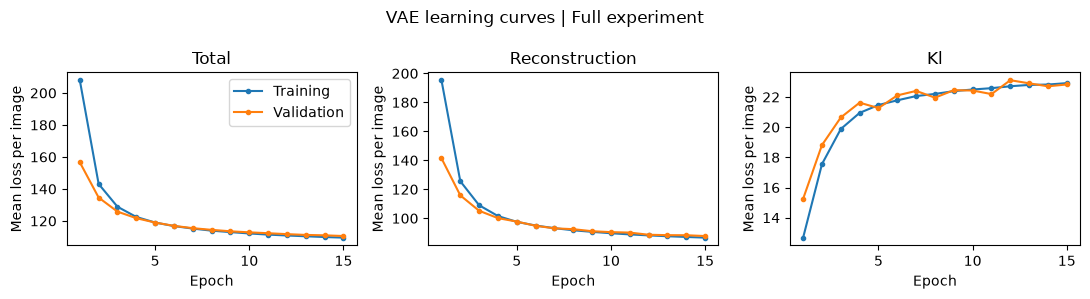

In [2]:
train, validation, support_pool = split_train(mnist(), settings, include_support=True)
assert len(set(train.indices + validation.indices + support_pool.indices)) == (
    len(train) + len(validation) + len(support_pool)
)
print(f"Representation: {len(train):,} | validation: {len(validation):,} | support pool: {len(support_pool):,}")
model, history = fit_or_load(settings, train, validation, device, conditional=False)
model.requires_grad_(False)
learning_curves(history, mode)
support = extract(model, support_pool, settings, device)
validation_latent, _, validation_labels = extract(model, validation, settings, device)

## Choose regularization on validation

One shot means one labeled support image per class. Each draw is a 10-way task with $10K$ labeled images. A Euclidean prototype classifier adapts by averaging the support features of each class, without gradient updates to the encoder. The linear classifier fits a regularized multinomial logistic regression on the same frozen support embeddings. In scikit-learn, smaller $C$ means stronger regularization. Select one $C$ per shot count by mean validation accuracy on a separate set of support draws.

In [3]:
shots = (1, 2, 5, 10, 20)
support_latent, _, support_labels = support
validation_draws = support_draws(support_labels, shots, 3 if quick else 10, settings.seed + 20)
regularization = {}
for k in shots:
    regularization[k], scores = select_regularization(
        support_latent, support_labels, validation_latent, validation_labels,
        validation_draws[k], candidates=(0.01, 0.1, 1.0, 10.0),
    )
    print(f"{k:2d} shots | selected C={regularization[k]:g} | validation scores {scores}")

 1 shots | selected C=1 | validation scores {0.01: np.float64(0.4156599999999999), 0.1: np.float64(0.42618), 1.0: np.float64(0.42665999999999993), 10.0: np.float64(0.42312000000000005)}


 2 shots | selected C=0.1 | validation scores {0.01: np.float64(0.52488), 0.1: np.float64(0.5397000000000001), 1.0: np.float64(0.53048), 10.0: np.float64(0.5224)}


 5 shots | selected C=0.1 | validation scores {0.01: np.float64(0.6506399999999999), 0.1: np.float64(0.6735), 1.0: np.float64(0.6700600000000001), 10.0: np.float64(0.65578)}


10 shots | selected C=0.1 | validation scores {0.01: np.float64(0.71782), 0.1: np.float64(0.7461599999999999), 1.0: np.float64(0.7363000000000001), 10.0: np.float64(0.7128)}


20 shots | selected C=0.1 | validation scores {0.01: np.float64(0.7630999999999999), 0.1: np.float64(0.78664), 1.0: np.float64(0.77684), 10.0: np.float64(0.7481)}


## Evaluate on the fixed test query set

Every method uses the same support examples for a given draw so differences in accuracy are not confounded with differences in which examples were labeled. Use 20 new draws for each shot count. In quick mode the query set is a fixed 1,000-image subset of the official test split. Set the diagnostic episode before inspecting results.

In [4]:
from torch.utils.data import Subset

diagnostic_k, diagnostic_draw = 5, 0
draws = support_draws(support_labels, shots, 20, settings.seed + 30)
test = mnist(train=False)
if quick:
    indices = np.random.default_rng(settings.seed + 31).choice(len(test), 1000, replace=False)
    test = Subset(test, indices.tolist())
query = extract(model, test, settings, device)
results, predictions = evaluate(support, query, draws, regularization)
print(f"{mode} | query images={len(test):,} | 20 draws per shot count")

Full experiment | query images=10,000 | 20 draws per shot count


**Full experiment**

| Shots per class | Raw pixel prototype | VAE prototype | VAE logistic regression |
| ---: | ---: | ---: | ---: |
| 1 | 41.1% ± 4.0% | 42.3% ± 3.7% | 42.5% ± 3.8% |
| 2 | 53.3% ± 3.0% | 52.8% ± 3.5% | 53.8% ± 3.5% |
| 5 | 65.5% ± 3.3% | 65.5% ± 3.9% | 67.4% ± 3.3% |
| 10 | 71.8% ± 1.8% | 72.7% ± 1.6% | 74.9% ± 1.3% |
| 20 | 75.8% ± 1.6% | 77.6% ± 1.1% | 79.8% ± 1.0% |

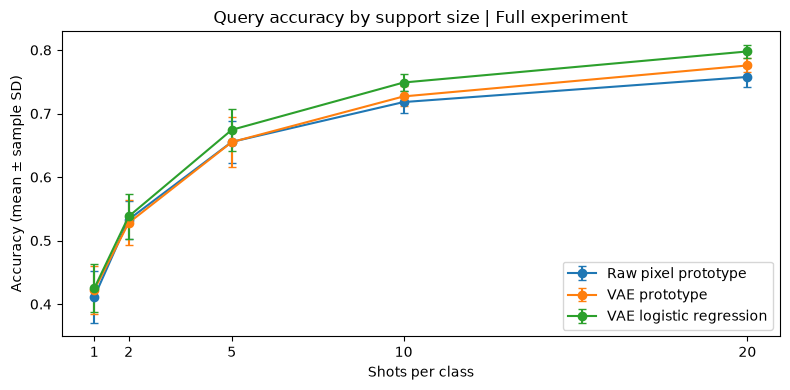

In [5]:
methods = list(results[shots[0]])
summary = [
    f"**{mode}**",
    "",
    "| Shots per class | " + " | ".join(methods) + " |",
    "| ---: | " + " | ".join(["---:"] * len(methods)) + " |",
]
fig, axis = plt.subplots(figsize=(8, 4))
for method in methods:
    means = [results[k][method].mean() for k in shots]
    deviations = [results[k][method].std(ddof=1) for k in shots]
    axis.errorbar(shots, means, yerr=deviations, marker="o", capsize=3, label=method)
for k in shots:
    row = [f"{results[k][m].mean():.1%} ± {results[k][m].std(ddof=1):.1%}" for m in methods]
    summary.append(f"| {k} | " + " | ".join(row) + " |")
display(Markdown("\n".join(summary)))
axis.set(title=f"Query accuracy by support size | {mode}", xlabel="Shots per class",
         ylabel="Accuracy (mean ± sample SD)", xticks=shots)
axis.legend()
fig.tight_layout()
plt.show()

The standard deviation describes variation across support draws with a fixed encoder and a fixed query set. The table reports measured results for all methods, including the raw-pixel baseline. More examples can improve estimates on average, but an individual draw can contain atypical examples that shift prototypes or change the fitted boundary. Draws at different shot counts can also contain different images.

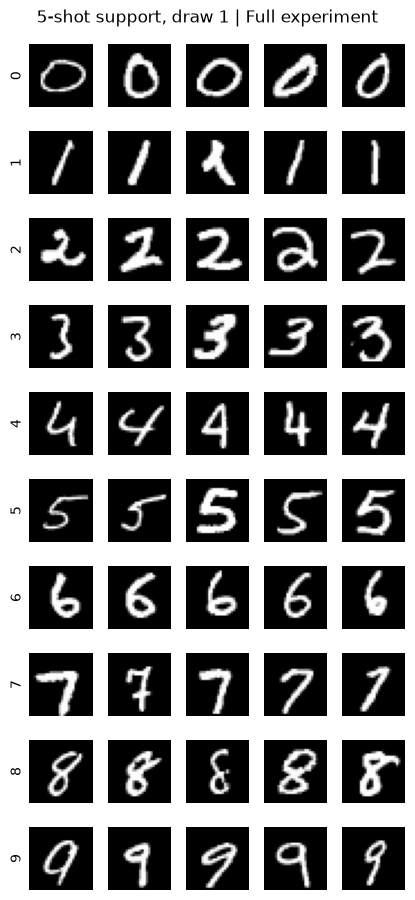

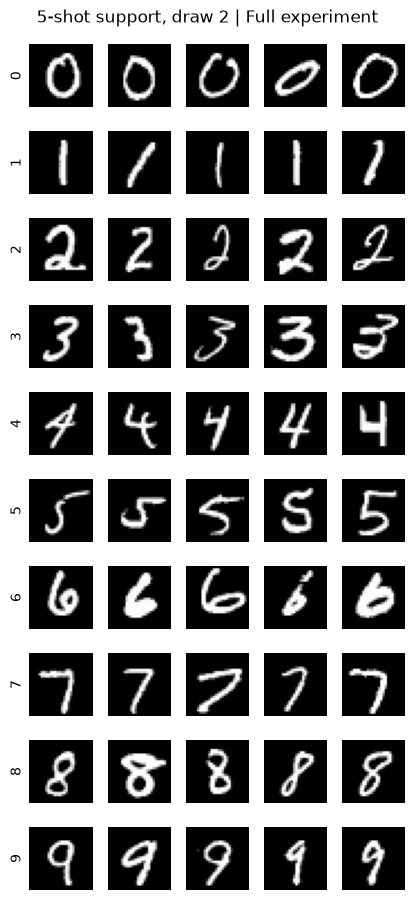

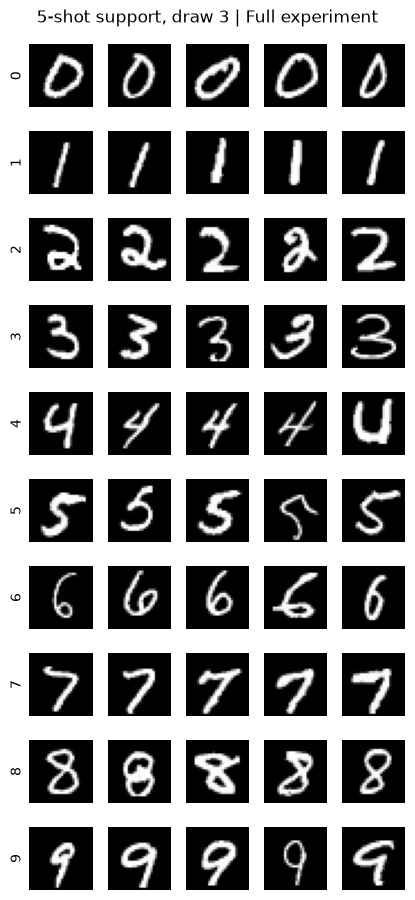

In [6]:
_, support_pixels, _ = support
for repetition in (0, 1, 2):
    ids = draws[diagnostic_k][repetition]
    image_grid(
        support_pixels[ids].reshape(10, diagnostic_k, 28, 28),
        f"{diagnostic_k}-shot support, draw {repetition + 1} | {mode}",
        row_labels=list(range(10)),
    )

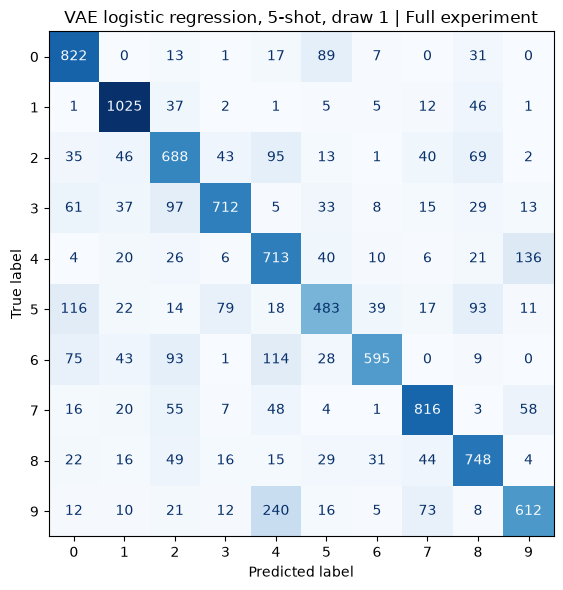

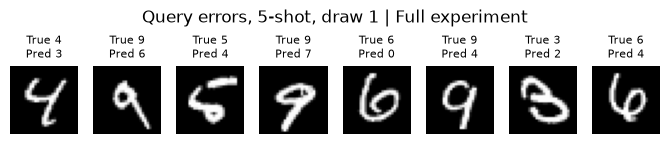

In [7]:
_, query_pixels, query_labels = query
predicted = predictions[diagnostic_k]["VAE logistic regression"][diagnostic_draw]
matrix = confusion_matrix(query_labels, predicted, labels=np.arange(10))
fig, axis = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(matrix).plot(ax=axis, cmap="Blues", colorbar=False)
axis.set_title(f"VAE logistic regression, {diagnostic_k}-shot, draw {diagnostic_draw + 1} | {mode}")
fig.tight_layout()
plt.show()

errors = np.flatnonzero(predicted != query_labels)[:8]
if len(errors):
    image_grid(
        query_pixels[errors].reshape(1, len(errors), 28, 28),
        f"Query errors, {diagnostic_k}-shot, draw {diagnostic_draw + 1} | {mode}",
        column_labels=[f"True {query_labels[i]}\nPred {predicted[i]}" for i in errors],
    )
else:
    print("No query errors in the fixed draw.")

## Visualize two principal components

Fit PCA on representation training embeddings and transform a labeled subset of query embeddings for display. The two axes capture some variation, and the projection can distort distances in the full latent space used by the classifiers.

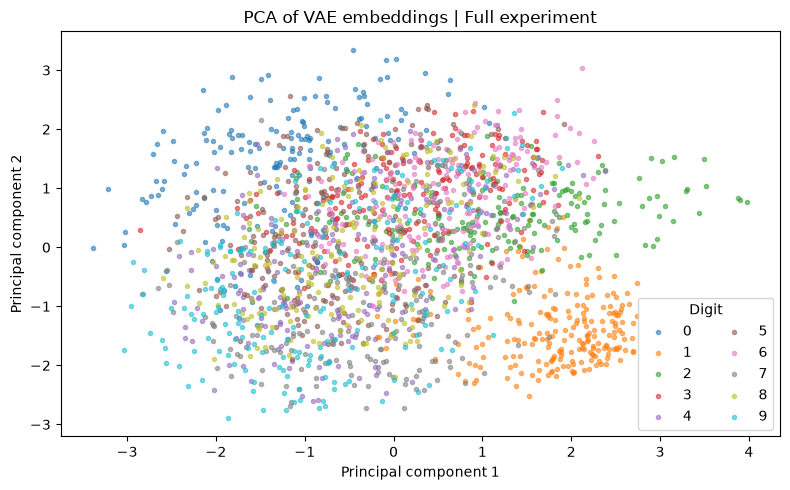

In [8]:
from threadpoolctl import threadpool_limits

train_latent, _, _ = extract(model, train, settings, device)
with threadpool_limits(limits=1):
    projection = PCA(n_components=2, random_state=settings.seed).fit(train_latent)
query_latent = query[0]
display_indices = np.random.default_rng(settings.seed + 40).choice(
    len(query_labels), min(2000, len(query_labels)), replace=False,
)
points = projection.transform(query_latent[display_indices])
labels = query_labels[display_indices]
fig, axis = plt.subplots(figsize=(8, 5))
for digit in range(10):
    group = points[labels == digit]
    axis.scatter(group[:, 0], group[:, 1], s=9, alpha=0.55, label=str(digit))
axis.set(title=f"PCA of VAE embeddings | {mode}", xlabel="Principal component 1",
         ylabel="Principal component 2")
axis.legend(title="Digit", ncol=2)
fig.tight_layout()
plt.show()